In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import os
import random
import traceback

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
import torch
import torch.nn.functional as F
from torch.utils._pytree import tree_map
from torch.utils.data import Dataset, DataLoader
from tqdm import tqdm

import data_loaders
from data_loaders import commit_dataset, CommitedDataset
from dl_trainer import Trainer
from rs_algorithm.models import AdaptiveRepresentation
from rs_algorithm.models import TwoTowerRecommender

In [3]:
os.getcwd()

'C:\\Beryllium Base\\WORKSPACES\\MTECH\\RS-project\\sandbox'

In [4]:
data_model = data_loaders.KuaiRecData(root='../data/KuaiRec2.0', initial_specimen='smaller')

In [5]:
data_model.ratings.head()

,user_id,item_id,rating,time
0,1520,1357,0.471552,2020-08-19 23:02:14.022
1,4984,8432,0.427609,2020-07-13 16:27:10.746
2,6474,3934,0.851681,2020-07-24 05:24:54.063
3,6435,6264,0.166174,2020-08-18 09:19:47.704
4,1094,8648,0.784189,2020-07-28 18:35:20.47


In [18]:
try:
    d_embed = 1024
    n_users, d_user_feats = data_model.user_features.shape
    n_items, d_item_feats = data_model.item_features.shape
    # n_users 7176 d_user_feats 1592
    # n_items 10728 d_item_feats 429

    n_users, d_user_feats = data_model.ratings['user_id'].nunique(), data_model.user_features.shape[1]
    n_items, d_item_feats = data_model.ratings['item_id'].nunique(), data_model.item_features.shape[1]
    # n_users 1411 d_user_feats 1592
    # n_items 3327 d_item_feats 429

    uid2idx = {v: i for i, v in enumerate(np.unique(data_model.ratings['user_id']))}
    user_model = AdaptiveRepresentation(n_users, d_user_feats, d_hidden=d_embed, d_embed=d_embed, id2idx=uid2idx)
    iid2idx = {v: i for i, v in enumerate(np.unique(data_model.ratings['item_id']))}
    item_model = AdaptiveRepresentation(n_items, d_item_feats, d_hidden=d_embed, d_embed=d_embed, id2idx=iid2idx)
    model = TwoTowerRecommender(user_model, item_model)
except:
    traceback.print_exc()

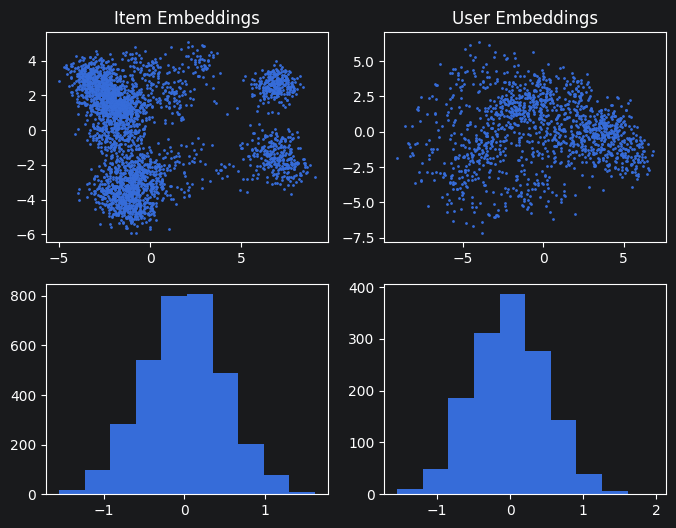

In [19]:
def _plot_tsne_pca_stuff(em, axem, bs, axbs):
    # weights = sklearn.decomposition.PCA(n_components=128).fit_transform(em)
    # weights = sklearn.manifold.TSNE(perplexity=10).fit_transform(weights)
    weights = sklearn.decomposition.PCA(n_components=2).fit_transform(em)
    axem.scatter(weights[:, 0], weights[:, 1], s=1)
    axbs.hist(bs)


@torch.no_grad()
def plot_tsne_pca_stuff():
    item_model.eval(), user_model.eval()
    _, axs = plt.subplots(2, 2, figsize=(8, 6))
    axs = axs.flatten()

    item_ids = data_model.ratings['item_id'].unique()
    item_feat = data_model.get_item_features(item_ids).astype(np.float32)
    iem, ibs = item_model(torch.tensor(item_ids), torch.tensor(item_feat))

    axs[0].set_title("Item Embeddings")
    _plot_tsne_pca_stuff(iem.cpu().numpy(), axs[0], ibs.cpu().numpy(), axs[2])
    del item_ids, item_feat, iem, ibs

    user_ids = data_model.ratings['user_id'].unique()
    user_feat = data_model.get_user_features(user_ids).astype(np.float32)
    uem, ubs = user_model(torch.tensor(user_ids), torch.tensor(user_feat))

    axs[1].set_title("User Embeddings")
    _plot_tsne_pca_stuff(uem.cpu().numpy(), axs[1], ubs.cpu().numpy(), axs[3])
    del user_ids, user_feat, uem, ubs

    plt.show()


try:
    pass
    plot_tsne_pca_stuff()
except:
    traceback.print_exc()

In [11]:
class VVICDatasetIdx(Dataset):
    def __init__(self, data_model: 'DataModel', ratings=None, paravalance=6):
        self.data_model = data_model
        self.ratings: pd.DataFrame = ratings if ratings is not None else data_model.ratings
        # self.ratings = self.ratings.sample(frac=1)
        self.median = 0.8
        self.paravalance = paravalance

        self.user_ids = self.ratings['user_id'].to_numpy()
        self.ratings_values = self.ratings['rating'].to_numpy()

        self.user_pos_indices = {}

        for idx, (u, r) in enumerate(zip(self.user_ids, self.ratings_values)):
            if r >= self.median:
                if u not in self.user_pos_indices:
                    self.user_pos_indices[u] = []
                self.user_pos_indices[u].append(idx)

        for u in self.user_pos_indices:
            self.user_pos_indices[u] = np.array(self.user_pos_indices[u])

        self.all_indices = np.arange(len(self.ratings))

    def __len__(self):
        return data_model.ratings.shape[0]

    def __getitem__(self, idx):
        user_id = self.user_ids[idx]

        pos_candidates = self.user_pos_indices[user_id]
        pos_id = pos_candidates[np.random.randint(len(pos_candidates))]

        neg_ids = np.random.choice(self.all_indices, size=self.paravalance)

        return user_id, pos_id, neg_ids


class VVICDataset(Dataset):
    def __init__(self, idx_data: VVICDatasetIdx, data_model: 'DataModel'):
        self.idx_data = idx_data
        self.data_model = data_model

    def __len__(self):
        return data_model.ratings.shape[0]

    def __getitem__(self, idx):
        user_id, pos_id, neg_ids = self.idx_data[idx]

        user_feat = self.data_model.get_user_features(user_id)

        pos_item_id, pos_item_rating = self.data_model.ratings.iloc[pos_id][['item_id', 'rating']]
        pos_item_feat = self.data_model.get_item_features(pos_item_id)

        neg_item_data = []
        neg_item_ratings = []
        for neg_id in neg_ids:
            neg_item_id, neg_item_rating = data_model.ratings.iloc[neg_id][['item_id', 'rating']]
            neg_item_feat = self.data_model.get_item_features(neg_item_id)
            neg_item_data.append((neg_item_id, neg_item_feat))
            neg_item_ratings.append(neg_item_rating.astype(np.float32))

        return (
            (
                user_id, user_feat,
                pos_item_id, pos_item_feat,
                neg_item_data
            ),
            (
                pos_item_rating.astype(np.float32),
                neg_item_ratings
            )
        )


class VVICDatasetV2(Dataset):
    def __init__(self, idx_data, data_model):
        self.idx_data = idx_data
        self.data_model = data_model

        df = data_model.ratings

        self.item_ids = df['item_id'].to_numpy()
        self.ratings = df['rating'].to_numpy(dtype=np.float32)

        self.user_features = data_model.user_features.sort_index().to_numpy()
        self.item_features = data_model.item_features.sort_index().to_numpy()

    def __len__(self):
        return self.data_model.ratings.shape[0]
        # return 100

    def __getitem__(self, idx):
        user_id, pos_id, neg_ids = self.idx_data[idx]

        user_feat = self.user_features[user_id]
        pos_item_id = self.item_ids[pos_id]
        pos_item_feat = self.item_features[pos_item_id]
        pos_rating = self.ratings[pos_id]

        neg_item_ids = self.item_ids[neg_ids]
        neg_item_feats = [self.item_features[i].astype(np.float32) for i in neg_item_ids]
        neg_ratings = tuple(self.ratings[neg_ids])

        neg_item_data = tuple(zip(neg_item_ids, neg_item_feats))

        return (
            (
                user_id, user_feat.astype(np.float32),
                pos_item_id, pos_item_feat.astype(np.float32),
                neg_item_data
            ),
            (
                pos_rating,
                neg_ratings
            )
        )


try:
    vvic = VVICDatasetV2(VVICDatasetIdx(data_model), data_model)
    (uid, uft, pii, pif, nid), (pir, nirs) = vvic[0]
    print("User", uid.dtype, uid, uft.dtype, uft.shape)
    print("PosI", pii.dtype, pii, pif.dtype, pif.shape, pir.dtype, pir)
    for (nii, nif), nirs in zip(nid, nirs):
        print("NegI", nii.dtype, nii, nif.dtype, nif.shape, nirs.dtype, nirs)
    print("AcNI", np.mean(nirs))
except:
    traceback.print_exc()

User int64 1520 float32 (1582,)
PosI int64 2339 float32 (429,) float32 0.95751286
NegI int64 3117 float32 (429,) float32 0.45855466
NegI int64 9995 float32 (429,) float32 1.6269225
NegI int64 4006 float32 (429,) float32 2.6571405
NegI int64 4082 float32 (429,) float32 0.73210573
NegI int64 5212 float32 (429,) float32 0.7146987
NegI int64 6285 float32 (429,) float32 0.58565015
AcNI 0.58565015


In [311]:
try:
    if False:
        commit_dataset(VVICDatasetIdx(data_model), "VVICDatasetIdx", os.path.join('..', 'temp', 'commited_datasets'))
except:
    traceback.print_exc()

100%|██████████| 998100/998100 [00:11<00:00, 88657.00it/s]


In [363]:
try:
    if False:
        vvic = VVICDataset(CommitedDataset('VVICDatasetIdx', os.path.join('..', 'temp', 'commited_datasets')), data_model)
except:
    traceback.print_exc()

In [455]:
try:
    if False:
        commit_dataset(vvic, "VVICDataset", os.path.join('..', 'temp', 'commited_datasets'))
except:
    traceback.print_exc()

100%|██████████| 998100/998100 [01:50<00:00, 9030.52it/s] 


In [12]:
try:
    if True:
        vvic = CommitedDataset('VVICDataset', os.path.join('..', 'temp', 'commited_datasets'))
except:
    traceback.print_exc()

In [13]:
def model_train_step(model, data):
    uid, uft, pii, pif, nid = data
    pos_score = model(uid, uft, pii, pif)[0]
    neg_scores = [model(uid, uft, nii, nif)[0] for nii, nif in nid]
    return pos_score, neg_scores


def model_criteria_step(criterion, preds, truth, weight=1.4):
    pos_score, neg_scores = preds
    pir, nirs = truth
    return criterion(pos_score, pir) + weight * sum(criterion(nsc, nir) for nsc, nir in zip(neg_scores, nirs)) / len(neg_scores)


def loss_fn_mse_only(preds, truth, median=torch.log1p(torch.tensor(0.8))):
    return F.mse_loss(preds, torch.log1p(truth) - median)


def running_average(arr, window=20):
    return np.convolve(arr, np.ones(window), 'valid') / window

## Training the model with focus only on feature based embeddings

Basically asking it to learn the task as closely as possible using only the user and item features

In [14]:
try:
    pre_training_loss = locals().get('pre_training_loss', None)
    pre_trainer = Trainer(
        model=model,
        train_dataloader=DataLoader(vvic, batch_size=8192, shuffle=True),
        criterion=loss_fn_mse_only,
        optimizer=lambda x: torch.optim.Adam(x, lr=0.003),
        epochs=1,
        record_per_epoch_training_loss=True,
        record_per_batch_training_loss=True,
        model_train_step=model_train_step,
        model_criteria_step=model_criteria_step,
        loss=pre_training_loss,
    )
    pre_training_loss = pre_trainer.loss
    pre_trainer.load_model('model_pretrained_feature_embedder_v3.pt')
except:
    traceback.print_exc()

In [553]:
try:
    pass
    pre_trainer.epochs = 1
    # pre_trainer.dataset_fraction = None
    pre_trainer.model_criteria_step = model_criteria_step
    # # pre_trainer.load_model('model_pretrained_feature_embedder_v3.pt')
    # pre_trainer.learning_rate(0.0003)
    pre_trainer.checkpoint_frequency_batch = 30
    # pre_trainer.device = 'cuda'
    pre_trainer.train_dataloader = DataLoader(vvic, batch_size=8192, shuffle=True)
except:
    traceback.print_exc()

In [554]:
try:
    model.prepare_for_feature_based_embeds_training()
    # TODO: Experiment with a lower dropout
    pre_trainer.train()
    # ds v1 CPU 33 sec/it
    # ds v1 GPU 26 sec/it
    # ds v2 GPU 7 sec/it
except:
    traceback.print_exc()

Epoch:  0/ 1    Train Loss: 0.47    TTS: 11.71    ETA: 1416.55
Epoch:  0/ 1    Train Loss: 0.47    TTS: 23.35    ETA: 1401.22
Epoch:  0/ 1    Train Loss: 0.47    TTS: 34.78    ETA: 1379.54
Epoch:  0/ 1    Train Loss: 0.47    TTS: 46.53    ETA: 1372.75
Epoch:  0/ 1    Train Loss: 0.47    TTS: 58.27    ETA: 1363.56
Epoch:  0/ 1    Train Loss: 0.47    TTS: 69.98    ETA: 1353.04
Epoch:  0/ 1    Train Loss: 0.47    TTS: 81.48    ETA: 1338.57
Epoch:  0/ 1    Train Loss: 0.47    TTS: 93.54    ETA: 1333.00
Epoch:  0/ 1    Train Loss: 0.48    TTS: 105.50    ETA: 1324.61
Epoch:  0/ 1    Train Loss: 0.48    TTS: 117.84    ETA: 1319.85
Epoch:  0/ 1    Train Loss: 0.48    TTS: 129.58    ETA: 1307.59
Epoch:  0/ 1    Train Loss: 0.48    TTS: 141.56    ETA: 1297.66
Epoch:  0/ 1    Train Loss: 0.47    TTS: 153.43    ETA: 1286.44
Epoch:  0/ 1    Train Loss: 0.47    TTS: 165.38    ETA: 1275.78
Epoch:  0/ 1    Train Loss: 0.47    TTS: 177.30    ETA: 1264.72
Epoch:  0/ 1    Train Loss: 0.47    TTS: 189.10 

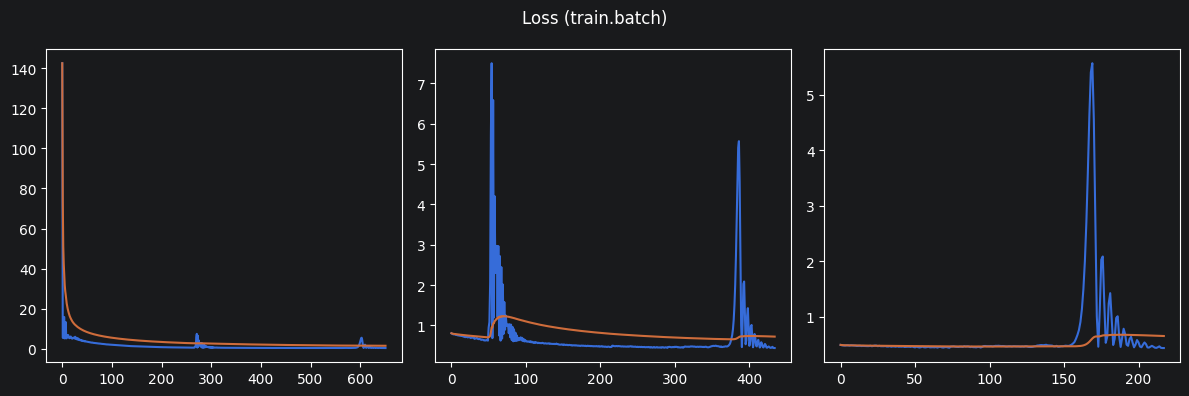

In [555]:
try:
    pre_trainer.plot_loss(skip=690)
except:
    traceback.print_exc()

In [556]:
try:
    # pre_trainer.loss['train.batch'] = pre_trainer.loss['train.batch'][:-10]
    print(len(pre_trainer.loss['train.batch']))
except:
    traceback.print_exc()

1342


In [557]:
try:
    for key in pre_trainer.timer.timers:
        print(key, pre_trainer.timer.timers[key].average)
except:
    traceback.print_exc()

train 1480.0284468000027
_train_step 848.4986579000033
train_dataloader 2.1549663603134066
batch 3.7155567297083962


In [558]:
try:
    pre_trainer.save_model("pretrained_feature_embedder_v3")
except:
    traceback.print_exc()

## Testing if the model really did learn something good

In [559]:
try:
    n_pos, n_neg = 0, 0
    pos_l, neg_l = [], []
    with torch.no_grad():
        model.prepare_for_feature_based_embeds_training()
        model.eval()
        model.to('cpu')
        temp_ds = DataLoader(vvic, batch_size=8192)
        for _, ((uid, uft, pii, pif, nid), (pir, nirs)) in zip(tqdm(range(10)), temp_ds):
            pos_score, neg_scores = model_train_step(model, (uid, uft, pii, pif, nid))
            pos_score, neg_scores = pos_score.numpy(), [x.numpy() for x in neg_scores]
            n_pos = n_pos + (pos_score > 0.0).sum()
            n_neg = n_neg + sum([(x < 0.0).sum() for x in neg_scores])
            pos_l.append(pos_score.mean()), neg_l.append(np.mean(neg_scores))
    print("POS SCORES")
    print("Accuracy: ", n_pos / len(vvic))
    print("Avg Weig: ", np.mean(pos_l))
    print("NEG SCORES")
    print("Accuracy: ", n_neg / len(vvic))
    print("Avg Weig: ", np.mean(neg_l))

    del pos_l, neg_l
except:
    traceback.print_exc()

100%|██████████| 10/10 [00:18<00:00,  1.81s/it]

POS SCORES
Accuracy:  0.0552850415790001
Avg Weig:  0.04166374
NEG SCORES
Accuracy:  0.20866346057509266
Avg Weig:  0.006717129


In [560]:
try:
    print("POS SCORES")
    print("Accuracy: ", n_pos / 81920)
    print("NEG SCORES")
    print("Accuracy: ", n_neg / 81920 / 6)
except:
    traceback.print_exc()

POS SCORES
Accuracy:  0.673583984375
NEG SCORES
Accuracy:  0.42372029622395835


## Training the model with focus only on item based embeddings

Allowing it to learn the the item based embeddings (and bias) to close the gap

In [21]:
try:
    id_training_loss = locals().get('id_training_loss', None)
    id_trainer = Trainer(
        model=model,
        train_dataloader=DataLoader(vvic, batch_size=8192),
        criterion=loss_fn_mse_only,
        optimizer=lambda x: torch.optim.Adam(x, lr=0.003),
        epochs=1,
        record_per_epoch_training_loss=True,
        record_per_batch_training_loss=True,
        model_train_step=model_train_step,
        model_criteria_step=model_criteria_step,
        loss=id_training_loss,
    )
    id_training_loss = id_trainer.loss
    # id_trainer.load_model("model_id_trained_embedder_v3.pt")
except:
    traceback.print_exc()

In [587]:
try:
    pass
    # id_trainer.load_model("model_id_trained_embedder_v3.pt")
    id_trainer.epochs = 1
    id_trainer.model_criteria_step = model_criteria_step
    # id_trainer.train_dataloader=DataLoader(vvic, batch_size=8192)
    # id_trainer.learning_rate(0.001)
except:
    traceback.print_exc()

In [612]:
try:
    model.prepare_for_id_based_embeds_training()
    id_trainer.train()
except:
    traceback.print_exc()

Epoch:  0/ 1    Train Loss: 0.32    TTS: 2.29    ETA: 276.60
Epoch:  0/ 1    Train Loss: 0.33    TTS: 4.64    ETA: 278.50
Epoch:  0/ 1    Train Loss: 0.33    TTS: 6.99    ETA: 277.11
Epoch:  0/ 1    Train Loss: 0.32    TTS: 9.33    ETA: 275.16
Epoch:  0/ 1    Train Loss: 0.32    TTS: 11.72    ETA: 274.16
Epoch:  0/ 1    Train Loss: 0.33    TTS: 14.01    ETA: 270.91
Epoch:  0/ 1    Train Loss: 0.33    TTS: 16.35    ETA: 268.60
Epoch:  0/ 1    Train Loss: 0.33    TTS: 18.71    ETA: 266.69
Epoch:  0/ 1    Train Loss: 0.33    TTS: 21.00    ETA: 263.67
Epoch:  0/ 1    Train Loss: 0.32    TTS: 23.36    ETA: 261.59
Epoch:  0/ 1    Train Loss: 0.32    TTS: 25.66    ETA: 258.90
Epoch:  0/ 1    Train Loss: 0.32    TTS: 28.04    ETA: 257.01
Epoch:  0/ 1    Train Loss: 0.32    TTS: 30.45    ETA: 255.28
Epoch:  0/ 1    Train Loss: 0.32    TTS: 32.70    ETA: 252.23
Epoch:  0/ 1    Train Loss: 0.32    TTS: 35.06    ETA: 250.11
Epoch:  0/ 1    Train Loss: 0.32    TTS: 37.35    ETA: 247.45
Epoch:  0/ 1

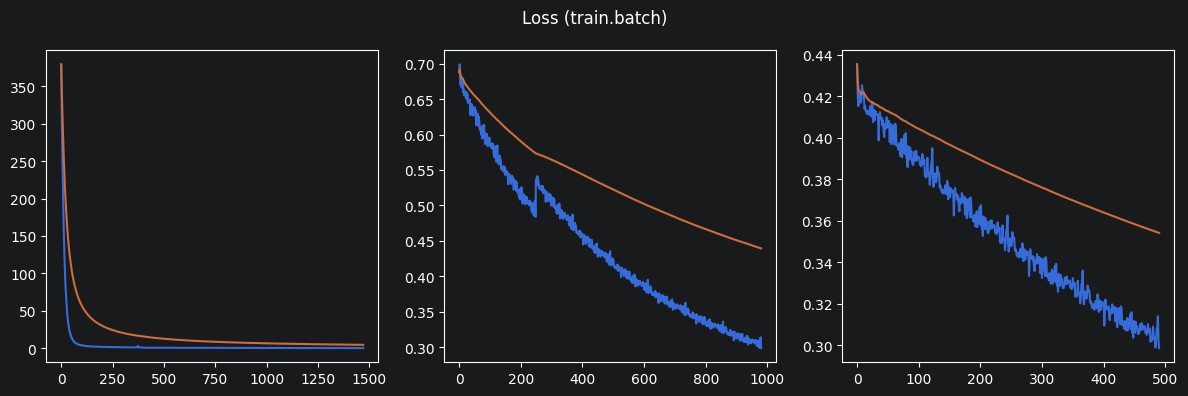

In [613]:
try:
    id_trainer.plot_loss(skip=0)
except:
    traceback.print_exc()

In [614]:
try:
    # id_trainer.loss['train.batch'] = id_trainer.loss['train.batch'][3000:]
    print(len(id_trainer.loss['train.batch']))
except:
    traceback.print_exc()

1471


In [615]:
try:
    for key in id_trainer.timer.timers:
        print(key, id_trainer.timer.timers[key].average)
except:
    traceback.print_exc()

train 794.0044214499998
_train_step 793.9348982083333
train_dataloader 4.871333606648603
batch 1.641010120190443


In [642]:
try:
    id_trainer.save_model("id_trained_embedder_v3")
except:
    traceback.print_exc()

## Testing if the model really did learn something good

In [617]:
try:
    n_pos, n_neg = 0, 0
    pos_l, neg_l = [], []
    with torch.no_grad():
        model.prepare_for_id_based_embeds_training()
        model.eval()
        d = torch.device('cpu')
        model.to(d)
        temp_ds = DataLoader(vvic, batch_size=8192)

        for _, ((uid, uft, pii, pif, nid), (pir, nirs)) in zip(tqdm(range(10)), temp_ds):
            (uid, uft, pii, pif, nid), (pir, nirs) = tree_map(lambda x: x.to(d), ((uid, uft, pii, pif, nid), (pir, nirs)))
            pos_score, neg_scores = model_train_step(model, (uid, uft, pii, pif, nid))
            pos_score, neg_scores = pos_score.cpu().numpy(), [x.cpu().numpy() for x in neg_scores]
            n_pos = n_pos + (pos_score > 0.0).sum()
            n_neg = n_neg + sum([(x < 0.0).sum() for x in neg_scores])
            pos_l.append(pos_score.mean()), neg_l.append(np.mean(neg_scores))
    print("POS SCORES")
    print("Accuracy: ", n_pos / len(vvic))
    print("Avg Weig: ", np.mean(pos_l))
    print("NEG SCORES")
    print("Accuracy: ", n_neg / len(vvic))
    print("Avg Weig: ", np.mean(neg_l))

    del pos_l, neg_l
except:
    traceback.print_exc()

100%|██████████| 10/10 [00:20<00:00,  2.09s/it]

POS SCORES
Accuracy:  0.05802725177837892
Avg Weig:  0.15169513
NEG SCORES
Accuracy:  0.2142841398657449
Avg Weig:  0.040490672


In [618]:
try:
    print("POS SCORES")
    print("Accuracy: ", n_pos / 81920)
    print("NEG SCORES")
    print("Accuracy: ", n_neg / 81920 / 6)
except:
    traceback.print_exc()

POS SCORES
Accuracy:  0.70699462890625
NEG SCORES
Accuracy:  0.43513387044270835


## Hmmm...

In [627]:
try:
    with torch.no_grad():
        model.eval()
        idx = random.randint(1, 1000)
        print(idx)  # 121
        (uid, uft, pii, pif, nid), (pir, nirs) = vvic[143]
        nid, nif = nid[0]
        nir = nirs[0]
        # (uid, uft, pii, pif, nid, nif), (pr, nr) = vvic[idx]
        uid, uft, pii, pif, nid, nif = (
            torch.tensor([uid], dtype=torch.int64), torch.tensor(uft[None, :], dtype=torch.float32),
            torch.tensor([pii], dtype=torch.int64), torch.tensor(pif[None, :], dtype=torch.float32),
            torch.tensor([nid], dtype=torch.int64), torch.tensor(nif[None, :], dtype=torch.float32))
        print("User ID:", uid)
        print("Pos  ID:", pii)
        print("Neg  ID:", nid)
        uem, _ = user_model(uid, uft, use_bias=False)
        pie, _ = item_model(pii, pif, use_bias=False)
        nie, _ = item_model(nid, nif, use_bias=False)
        print("Feat Only Dot Pos:", (uem * pie).sum(dim=1))
        print("Feat Only Dot Neg:", (uem * nie).sum(dim=1))
        uem, ubs = user_model(uid, uft, use_bias=True)
        pie, pib = item_model(pii, pif, use_bias=True)
        nie, nib = item_model(nid, nif, use_bias=True)
        print("With ID   Dot Pos:", (uem * pie).sum(dim=1) + ubs + pib)
        print("With ID   Dot Neg:", (uem * nie).sum(dim=1) + ubs + nib)
        model.prepare_for_feature_based_embeds_training()
        pos, neg, *_ = model(uid, uft, pii, pif, nid, nif)
        print("Model FO      Pos:", pos)
        print("Model FO      Neg:", neg)
        model.prepare_for_id_based_embeds_training()
        pos, neg, *_ = model(uid, uft, pii, pif, nid, nif)
        print("Model WB      Pos:", pos)
        print("Model WB      Neg:", neg)
        print("Ground Truth  Pos:", pir - np.log1p(0.8))
        print("Ground Truth  Neg:", nir - np.log1p(0.8))
except:
    traceback.print_exc()

755
User ID: tensor([6018])
Pos  ID: tensor([4740])
Neg  ID: tensor([6059])
Feat Only Dot Pos: tensor([0.2595])
Feat Only Dot Neg: tensor([-0.2289])
With ID   Dot Pos: tensor([0.2126])
With ID   Dot Neg: tensor([-0.2012])
Model FO      Pos: tensor([0.2595])
Model FO      Neg: tensor([-0.2289])
Model WB      Pos: tensor([0.2126])
Model WB      Neg: tensor([-0.2012])
Ground Truth  Pos: 0.9031748867641407
Ground Truth  Neg: -0.44746497803821983


# Oi?

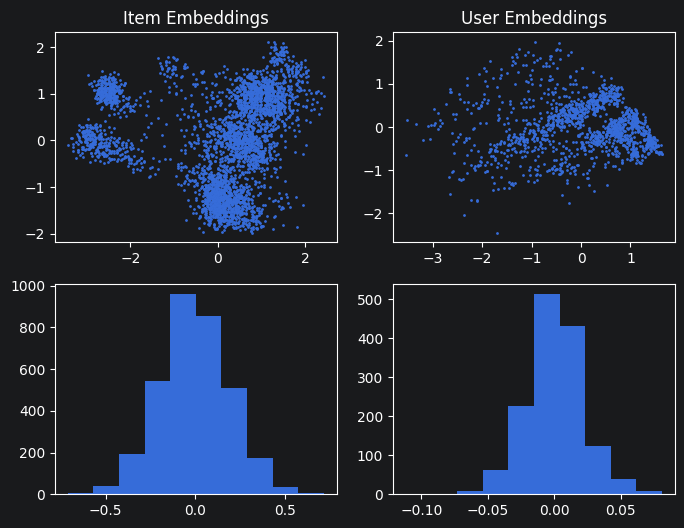

In [22]:
try:
    plot_tsne_pca_stuff()
except:
    traceback.print_exc()